# Projet PCG

### Membres :
- Oualid
- Julien
- Aurélien Blanco

##### Installation des librairies Pytorch
- Pour ceux qui possèdent CUDA Toolkit faire :
    - pip3 install torch torchvision torchaudio torchcodec --index-url https://download.pytorch.org/whl/cu126

In [1]:
import os

from src.preprocess import PCGDataset
from src.preprocess.representation import plot_waveform
from src.preprocess.representation import plot_spectrogram
from src.preprocess.representation import plot_fbank
from src.preprocess.representation import plot_pitch
 
from torch.utils.data import DataLoader

import torchaudio 
import torchaudio.functional as F
import torchaudio.transforms as T

from IPython.display import Audio
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

In [2]:
# print(torch.__version__)
print(torchaudio.__version__)

2.11.0+cu126


# Pré traitement

In [3]:
DATA_FOLDER = "classification-of-heart-sound-recordings-the-physionetcomputing-in-cardiology-challenge-2016-1.0.0" # Path to data folder

In [ ]:
SAMPLE_SPEECH = "classification-of-heart-sound-recordings-the-physionetcomputing-in-cardiology-challenge-2016-1.0.0/training-a/a0001.wav"

### Spectrogram

In [5]:
# Load audio
SPEECH_WAVEFORM, SAMPLE_RATE = torchaudio.load(SAMPLE_SPEECH)

# Define transform
spectrogram = T.Spectrogram(n_fft=512)

# Perform transform
spec = spectrogram(SPEECH_WAVEFORM)

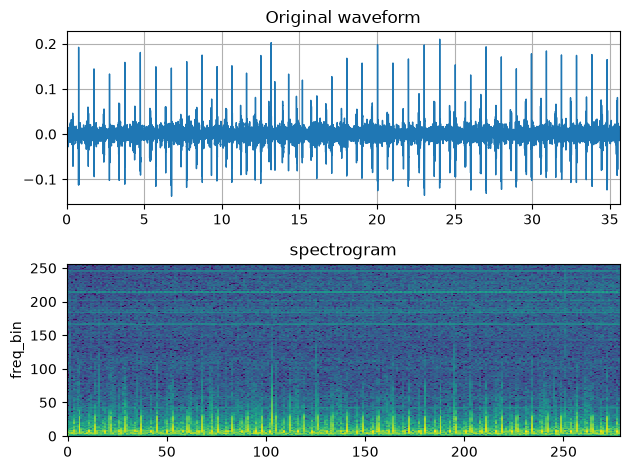

In [6]:
fig, axs = plt.subplots(2, 1)
plot_waveform(SPEECH_WAVEFORM, SAMPLE_RATE, title="Original waveform", ax=axs[0])
plot_spectrogram(spec[0], title="spectrogram", ax=axs[1])
fig.tight_layout()

In [7]:
Audio(SPEECH_WAVEFORM.numpy(), rate=SAMPLE_RATE)

In [8]:
n_ffts = [32, 128, 512, 2048]
hop_length = 64

specs = []
for n_fft in n_ffts:
    spectrogram = T.Spectrogram(n_fft=n_fft, hop_length=hop_length)
    spec = spectrogram(SPEECH_WAVEFORM)
    specs.append(spec)

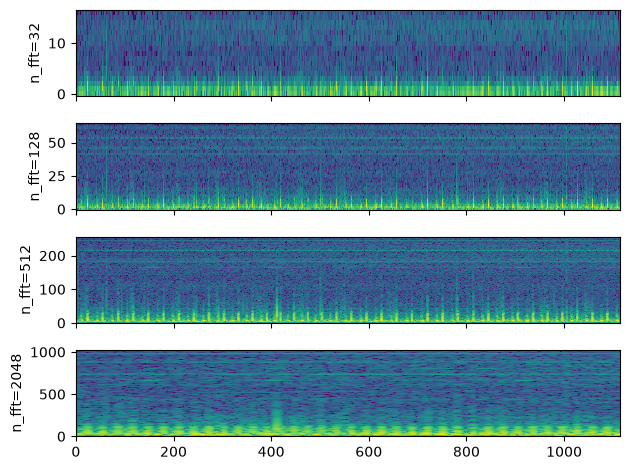

In [9]:
fig, axs = plt.subplots(len(specs), 1, sharex=True)
for i, (spec, n_fft) in enumerate(zip(specs, n_ffts)):
    plot_spectrogram(spec[0], ylabel=f"n_fft={n_fft}", ax=axs[i])
    axs[i].set_xlabel(None)
fig.tight_layout()

In [10]:
# Downsample to half of the original sample rate
speech2 = F.resample(SPEECH_WAVEFORM, SAMPLE_RATE, SAMPLE_RATE // 2)
# Upsample to the original sample rate
speech3 = F.resample(speech2, SAMPLE_RATE // 2, SAMPLE_RATE)

In [11]:
# Apply the same spectrogram
spectrogram = T.Spectrogram(n_fft=512)

spec0 = spectrogram(SPEECH_WAVEFORM)
spec2 = spectrogram(speech2)
spec3 = spectrogram(speech3)

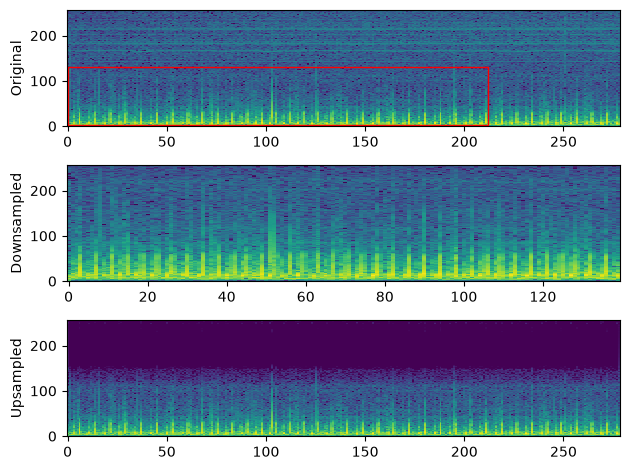

In [12]:
# Visualize it
fig, axs = plt.subplots(3, 1)
plot_spectrogram(spec0[0], ylabel="Original", ax=axs[0])
axs[0].add_patch(Rectangle((0, 3), 212, 128, edgecolor="r", facecolor="none"))
plot_spectrogram(spec2[0], ylabel="Downsampled", ax=axs[1])
plot_spectrogram(spec3[0], ylabel="Upsampled", ax=axs[2])
fig.tight_layout()

### GriffinLim

In [13]:
# Define transforms
n_fft = 1024
spectrogram = T.Spectrogram(n_fft=n_fft)
griffin_lim = T.GriffinLim(n_fft=n_fft)

# Apply the transforms
spec = spectrogram(SPEECH_WAVEFORM)
reconstructed_waveform = griffin_lim(spec)

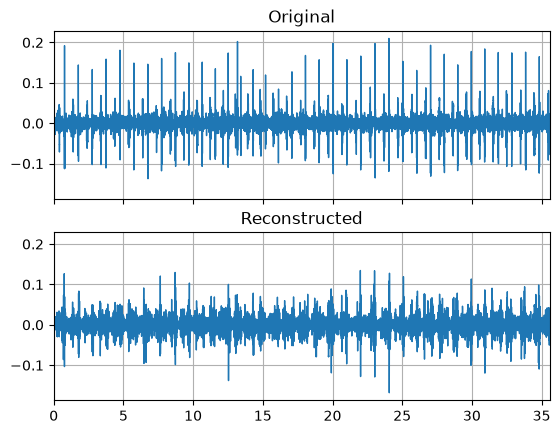

In [14]:
_, axes = plt.subplots(2, 1, sharex=True, sharey=True)
plot_waveform(SPEECH_WAVEFORM, SAMPLE_RATE, title="Original", ax=axes[0])
plot_waveform(reconstructed_waveform, SAMPLE_RATE, title="Reconstructed", ax=axes[1])
Audio(reconstructed_waveform, rate=SAMPLE_RATE)

### Mel Filter Bank

In [15]:
n_fft = 256
n_mels = 64
sample_rate = 6000

mel_filters = F.melscale_fbanks(
    int(n_fft // 2 + 1),
    n_mels=n_mels,
    f_min=0.0,
    f_max=sample_rate / 2.0,
    sample_rate=sample_rate,
    norm="slaney",
)

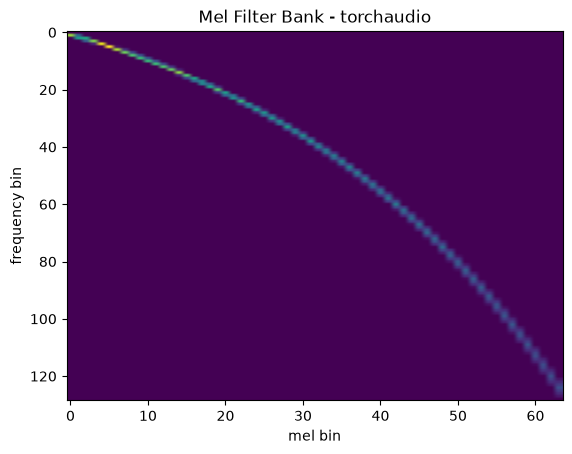

In [16]:
plot_fbank(mel_filters, "Mel Filter Bank - torchaudio")

### MelSpectrogram

In [17]:
n_fft = 1024
win_length = None
hop_length = 512
n_mels = 128

mel_spectrogram = T.MelSpectrogram(
    sample_rate=sample_rate,
    n_fft=n_fft,
    win_length=win_length,
    hop_length=hop_length,
    center=True,
    pad_mode="reflect",
    power=2.0,
    norm="slaney",
    n_mels=n_mels,
    mel_scale="htk",
)

melspec = mel_spectrogram(SPEECH_WAVEFORM)

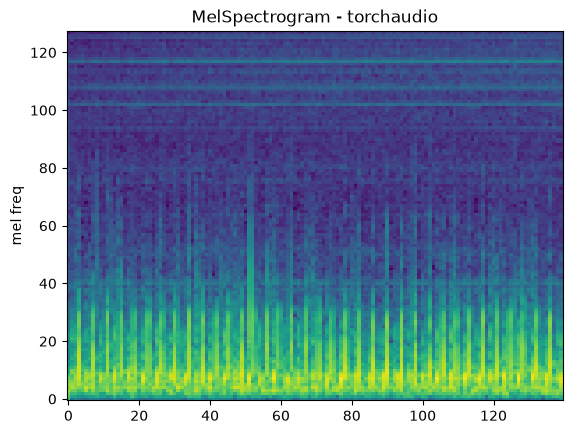

In [18]:
plot_spectrogram(melspec[0], title="MelSpectrogram - torchaudio", ylabel="mel freq")

### MFCC

In [19]:
n_fft = 2048
win_length = None
hop_length = 512
n_mels = 256
n_mfcc = 256

mfcc_transform = T.MFCC(
    sample_rate=sample_rate,
    n_mfcc=n_mfcc,
    melkwargs={
        "n_fft": n_fft,
        "n_mels": n_mels,
        "hop_length": hop_length,
        "mel_scale": "htk",
    },
)

mfcc = mfcc_transform(SPEECH_WAVEFORM)

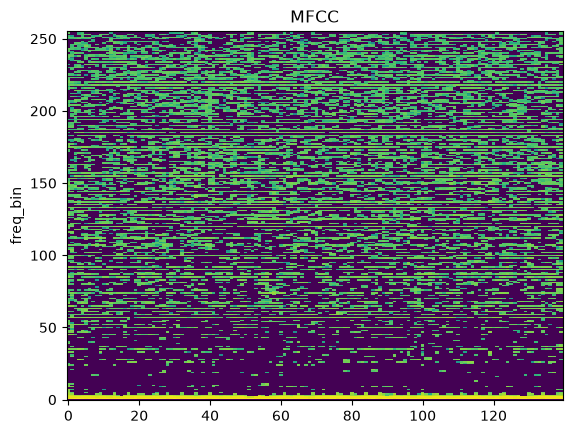

In [20]:
plot_spectrogram(mfcc[0], title="MFCC")

### LFCC

In [21]:
n_fft = 2048
win_length = None
hop_length = 512
n_lfcc = 256

lfcc_transform = T.LFCC(
    sample_rate=sample_rate,
    n_lfcc=n_lfcc,
    speckwargs={
        "n_fft": n_fft,
        "win_length": win_length,
        "hop_length": hop_length,
    },
)

lfcc = lfcc_transform(SPEECH_WAVEFORM)

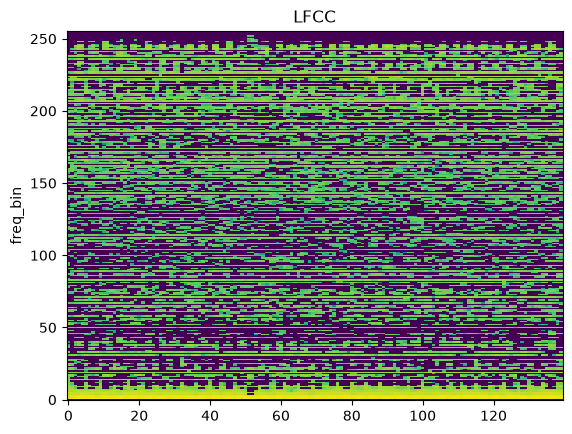

In [22]:
plot_spectrogram(lfcc[0], title="LFCC")

### Pitch

In [23]:
pitch = F.detect_pitch_frequency(SPEECH_WAVEFORM, SAMPLE_RATE)

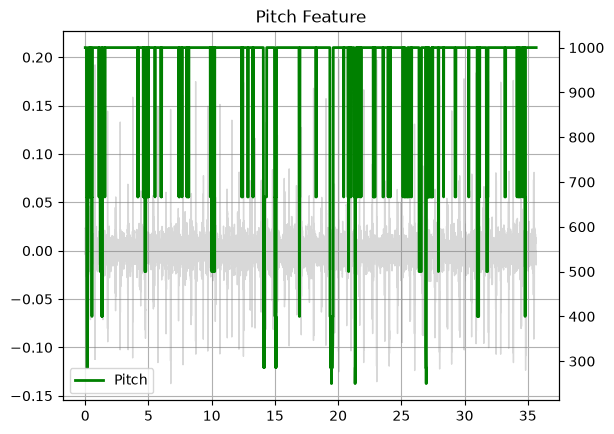

In [27]:
plot_pitch(SPEECH_WAVEFORM, SAMPLE_RATE, pitch)

# Chargement des données

In [26]:
dataset = PCGDataset(root_dir = DATA_FOLDER)

Successfully loaded 3240 audio files.
